# 02 · Labels v3 from the v2 masks

Makes the v3 label masks for every scene that already has an image and a v2 mask: the 383 simulated PhiSat-2 scenes, the 3 Sentinel-2 test chips and the 25 HEO scenes we started with. The HEO products in `data/heo/products/` are not done here; notebook 03 labels them from their band files.

Only the burnt area changes from v2. Clouds, shadows, water and no data are taken as they are. For each scene we take the EFFIS polygons that touch it and look at how old each fire was on the image date:

| fire age on the image date | label |
|---|---|
| 0 to 90 days | fresh burn (2) |
| 90 to 365 days | old burn (3) |
| more than a year, or after the image | clear (0), or water (6) where NDWI > 0.05 |

Then the pixels we don't trust become ignore (254): a band of about 10 m on both sides of every burn polygon edge, and burn pixels that look like vegetation (NDVI > 0.5) or are very bright (mean of blue, green and red reflectance > 0.3). Ignore pixels are left out of training and out of the scores. The rules are in `burnscar/labels.py`.

In v2, any fire more than 90 days before the image was old burn, however long ago it was. Step 3 shows how much of the burnt area that was, and why v3 stops at a year.

The v2 masks are only read. The v3 masks go to `masks_v3/` next to each `masks_v2/` folder, and the class counts of every scene to `data/tables/labels_v3_from_v2.csv`. Nothing is written before step 6, and only with `WRITE = True`. Run it one cell at a time.

## 1 · Setup, and the masks we use

In [1]:
# [1] setup, and the v2 masks this notebook uses
%cd ~/projects/iride_onboard-burnscar-mapper
import os, sys, glob, json, importlib
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import rasterio
from rasterio.enums import Resampling
from shapely.geometry import box
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
open("burnscar/__init__.py", "a").close()
import burnscar.labels as L
importlib.reload(L)

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
C_BLUE, C_ORANGE, C_GREY, INK2 = "#2a78d6", "#eb6834", "#8a8984", "#52514e"
SRC_NAME = {"phisat2_sim": "PhiSat-2 sim", "heo": "HEO", "s2_test": "Sentinel-2 test"}
SRC_COLOR = {"phisat2_sim": C_BLUE, "heo": C_ORANGE, "s2_test": C_GREY}
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2})
CMAP = ListedColormap([L.V3_COLORS[v] for v in L.V3_VALUES])
NORM = BoundaryNorm([-0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 200, 254.5, 255.5], CMAP.N)
WORKERS = 8      # parallel processes in steps 5 and 6, lower it if the machine runs out of memory

# HEO products are labelled from their band files in notebook 03, so their old masks are skipped here
products = {os.path.basename(p) for p in glob.glob("data/heo/products/IMH*")}
MASKS, rows = [], []
for src in ("phisat2_sim", "s2_test", "heo"):
    for m in sorted(glob.glob(f"data/{src}/masks_v2/*_mask.tif")):
        sid = L.scene_id_from_mask_path(m)
        if sid in products:
            use = "no, notebook 03 (product)"
        elif L.find_image_for_mask(m) is None:
            use = "no, image missing"
        else:
            use = "yes"
            MASKS.append(m)
        rows.append(dict(source=src, scene=sid, used=use))
inventory = pd.DataFrame(rows)
inventory.groupby(["source", "used"]).size().unstack(fill_value=0)
# expected: heo 25 yes and 4 products, phisat2_sim 383 yes, s2_test 3 yes

/root/projects/iride_onboard-burnscar-mapper


used,"no, notebook 03 (product)",yes
source,,
heo,4,25
phisat2_sim,0,383
s2_test,0,3


## 2 · Settings and EFFIS

In [2]:
# [2] settings and EFFIS
cfg = L.RelabelConfig()      # v3 as defined in burnscar/labels.py
print(asdict(cfg))

fires, parts = L.load_fires_merged(L.EFFIS_FILES)
for p, g in zip(L.EFFIS_FILES, parts):
    print(f"{os.path.basename(p)}: {len(g):,} polygons, fires from {g.fire_date.min().date()} to {g.fire_date.max().date()}")
print(f"together: {len(fires):,} polygons ({sum(map(len, parts)) - len(fires):,} fires were in both files, the newer one is kept)")
newest = max(L.parse_acq_datetime(L.scene_id_from_mask_path(m)) for m in MASKS)
print(f"newest image {newest.date()}, last EFFIS fire {fires.fire_date.max().date()}")

{'fresh_max': 90.0, 'old_max': 365.0, 'ignore_max': 365.0, 'edge_m': 10.0, 'ndwi_threshold': 0.05, 'ndvi_max': 0.5, 'bright_max': 0.3}
effis_IT-FR-ES-EL_2020-01-01_2026-08-03.zip: 25,707 polygons, fires from 2020-01-01 to 2026-08-03
effis_IT_2026-03-01_2026-10-05.json: 2,262 polygons, fires from 2026-03-01 to 2026-10-05
together: 26,824 polygons (1,145 fires were in both files, the newer one is kept)
newest image 2026-08-04, last EFFIS fire 2026-10-05


## 3 · How old is the burnt area v2 called old

Every EFFIS polygon that touches a scene, weighted by its area inside the scene, grouped by the age of the fire on the image date.

In [3]:
# [3] age of the burnt area in the scenes
rows = []
for m in MASKS:
    sid = L.scene_id_from_mask_path(m)
    with rasterio.open(m) as s:
        crs, b = s.crs, s.bounds
    sf = L.scene_fires(fires, crs, b, L.parse_acq_datetime(sid))
    if len(sf):
        rows.append(pd.DataFrame({"scene": sid, "source": L.source_of(m), "fire_id": sf.fire_id.values,
                                  "age_days": sf.age_days.values,
                                  "ha_in_scene": sf.geometry.intersection(box(*b)).area.values / 1e4}))
ages = pd.concat(rows, ignore_index=True)

BUCKETS = ["after image", "0–90 d", "90–120 d", "120–365 d", "1–2 years", "> 2 years"]
a = ages.age_days
ages["bucket"] = pd.Categorical(np.select([a < 0, a <= 90, a <= 120, a <= 365, a <= 730], BUCKETS[:5],
                                          default=BUCKETS[5]), BUCKETS, ordered=True)
area = ages.pivot_table(index="bucket", columns="source", values="ha_in_scene", aggfunc="sum", observed=False).fillna(0)
share = 100 * area / area.sum()
for src, g in ages.groupby("source"):
    tot = g.ha_in_scene.sum()
    v2_old = 100 * g.ha_in_scene[g.age_days > cfg.fresh_max].sum() / tot
    v3_old = 100 * g.ha_in_scene[(g.age_days > cfg.fresh_max) & (g.age_days <= cfg.old_max)].sum() / tot
    print(f"{SRC_NAME[src]}: v2 called {v2_old:.1f}% of the burnt-polygon area old, v3 keeps {v3_old:.1f}% as old")
pd.concat({"hectares": area.round(0), "% of area": share.round(1)}, axis=1)

HEO: v2 called 77.2% of the burnt-polygon area old, v3 keeps 11.1% as old
PhiSat-2 sim: v2 called 26.0% of the burnt-polygon area old, v3 keeps 2.4% as old
Sentinel-2 test: v2 called 22.9% of the burnt-polygon area old, v3 keeps 10.4% as old


hectares                     % of area                    
source           heo phisat2_sim s2_test       heo phisat2_sim s2_test
bucket                                                                
after image   5444.0   1090217.0   911.0      15.7        29.4    66.3
0–90 d        2444.0   1652312.0   148.0       7.1        44.6    10.8
90–120 d         6.0     13387.0     0.0       0.0         0.4     0.0
120–365 d     3818.0     74855.0   143.0      11.0         2.0    10.4
1–2 years     2258.0    222145.0   138.0       6.5         6.0    10.1
> 2 years    20607.0    654187.0    33.0      59.6        17.6     2.4

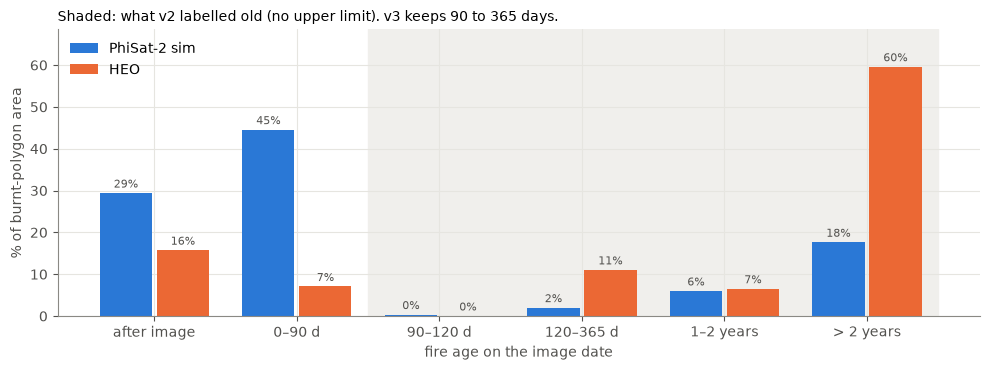

In [4]:
# [4] plot of [3], for the two training sources
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(BUCKETS))
srcs = [s for s in ["phisat2_sim", "heo"] if s in share.columns]
w = 0.8 / len(srcs)
for i, src in enumerate(srcs):
    bars = ax.bar(x + (i - (len(srcs) - 1) / 2) * w, share[src].values, w * 0.92, color=SRC_COLOR[src],
                  label=SRC_NAME[src])
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8, color=INK2, padding=2)
ax.axvspan(1.5, 5.5, color="#f0efec", zorder=0)
ax.set_ylim(0, float(share[srcs].values.max()) * 1.15)
ax.set_xticks(x); ax.set_xticklabels(BUCKETS)
ax.set_ylabel("% of burnt-polygon area"); ax.set_xlabel("fire age on the image date")
ax.set_title(f"Shaded: what v2 labelled old (no upper limit). v3 keeps {cfg.fresh_max:.0f} to {cfg.old_max:.0f} days.",
             loc="left", fontsize=10)
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 4 · One scene, v2 next to v3

Starts with the scene that has the most burnt area older than a year. Set `SAMPLE` to any scene name to look at another one. Pink is ignore.

In [5]:
# [5] one scene
older = ages[ages.age_days > cfg.old_max].groupby("scene").ha_in_scene.sum().sort_values(ascending=False)
SAMPLE = older.index[0]
mask_path = next(m for m in MASKS if L.scene_id_from_mask_path(m) == SAMPLE)
res = L.relabel_scene(mask_path, fires, cfg)
print(SAMPLE)
display(pd.Series(res["row"]).drop("mask_v2").to_frame("value").T)
res["fires"][["fire_id", "fire_date", "age_days", "area_ha"]].sort_values("age_days").round(1)

effis_561729_2026-08-04T10-00-23


,scene,source,status,acq,px_m,n_fires_fresh,n_fires_old,n_fires_ignore,n_fires_older,n_fires_future,v2_clear,v2_fresh,v2_old,v2_cloud,v2_shadow,v2_water,v2_ignore,v2_nodata,v3_clear,v3_fresh,v3_old,v3_cloud,v3_shadow,v3_water,v3_ignore,v3_nodata,changed_px
value,effis_561729_2026-08-04T10-00-23,phisat2_sim,ok,2026-08-04T10:00:23,4.75,20,27,0,200,21,9581902,864841,6328025,0,0,2448,0,0,14347794,1000960,1191975,0,0,4206,232281,0,5278575


/tmp/ipykernel_1037479/3620858645.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  res["fires"][["fire_id", "fire_date", "age_days", "area_ha"]].sort_values("age_days").round(1)


,fire_id,fire_date,age_days,area_ha
25521,effis_808942,2026-10-02 11:40:00.000,-59.1,16
25323,effis_816086,2026-09-30 12:19:00.000,-57.1,25
26412,effis_797595,2026-09-29 12:00:00.000,-56.1,2
25604,effis_797592,2026-09-29 12:00:00.000,-56.1,14
25128,effis_792692,2026-09-26 12:12:00.000,-53.1,39
...,...,...,...,...
9057,effis_40156,2020-07-01 09:12:01.296,2225.0,23
8314,effis_40155,2020-07-01 09:10:58.651,2225.0,26
6213,effis_40113,2020-06-25 12:02:55.203,2230.9,39
7733,effis_26277,2020-06-10 11:20:12.622,2245.9,29


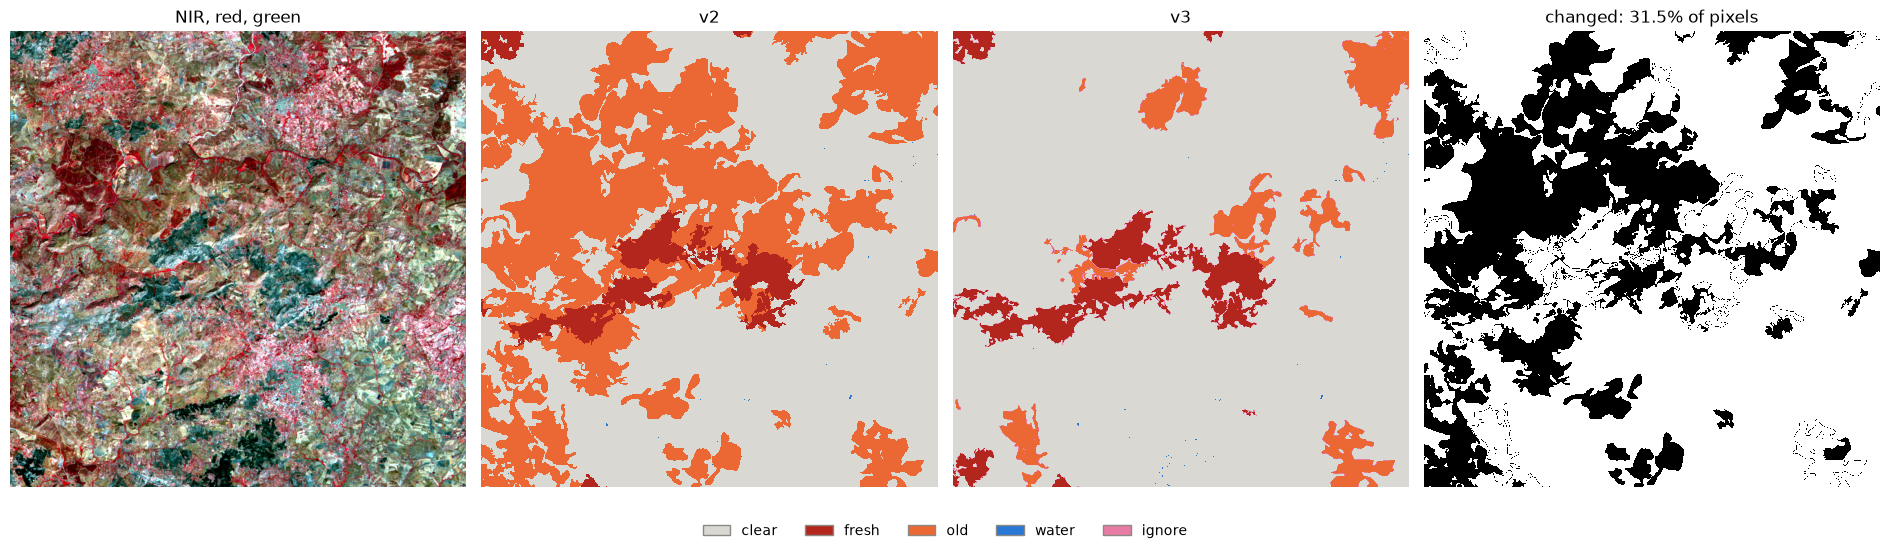

In [6]:
# [6] false colour | v2 | v3 | pixels that changed
def false_colour(img_path, decim):
    with rasterio.open(img_path) as s:
        g, nir = L.green_nir_band_indexes(s)
        h, w = s.height // decim, s.width // decim
        a = s.read([nir, g + 1, g], out_shape=(3, h, w), resampling=Resampling.nearest).astype(np.float32)
    valid = (a > 0).all(0)
    out = np.ones((h, w, 3), np.float32)
    for i in range(3):
        lo, hi = np.percentile(a[i][valid], (2, 98)) if valid.any() else (0, 1)
        out[..., i] = np.clip((a[i] - lo) / max(hi - lo, 1e-6), 0, 1)
    out[~valid] = 1
    return out

def show_v2_v3(res, img_path, decim=4):
    m2, m3 = res["m2"][::decim, ::decim], res["m3"][::decim, ::decim]
    fig, ax = plt.subplots(1, 4, figsize=(19, 5.4))
    ax[0].imshow(false_colour(img_path, decim)); ax[0].set_title("NIR, red, green")
    ax[1].imshow(m2, cmap=CMAP, norm=NORM, interpolation="nearest"); ax[1].set_title("v2")
    ax[2].imshow(m3, cmap=CMAP, norm=NORM, interpolation="nearest"); ax[2].set_title("v3")
    ax[3].imshow(m2 != m3, cmap="Greys", interpolation="nearest")
    ax[3].set_title(f"changed: {(res['m2'] != res['m3']).mean() * 100:.1f}% of pixels")
    for a in ax:
        a.axis("off")
    present = sorted(set(np.unique(res["m2"]).tolist()) | set(np.unique(res["m3"]).tolist()))
    fig.legend(handles=[Patch(facecolor=L.V3_COLORS[v], edgecolor="#8a8984", label=L.V3_NAMES[v]) for v in present],
               loc="lower center", ncol=len(present))
    plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

show_v2_v3(res, L.find_image_for_mask(mask_path), decim=1 if L.source_of(mask_path) == "s2_test" else 4)

In [10]:
# [5] one scene
older = ages[ages.age_days > cfg.old_max].groupby("scene").ha_in_scene.sum().sort_values(ascending=False)
SAMPLE = "effis_205433_2022-07-17T11-08-52"
mask_path = next(m for m in MASKS if L.scene_id_from_mask_path(m) == SAMPLE)
res = L.relabel_scene(mask_path, fires, cfg)
print(SAMPLE)
display(pd.Series(res["row"]).drop("mask_v2").to_frame("value").T)
res["fires"][["fire_id", "fire_date", "age_days", "area_ha"]].sort_values("age_days").round(1)

effis_205433_2022-07-17T11-08-52


,scene,source,status,acq,px_m,n_fires_fresh,n_fires_old,n_fires_ignore,n_fires_older,n_fires_future,v2_clear,v2_fresh,v2_old,v2_cloud,v2_shadow,v2_water,v2_ignore,v2_nodata,v3_clear,v3_fresh,v3_old,v3_cloud,v3_shadow,v3_water,v3_ignore,v3_nodata,changed_px
value,effis_205433_2022-07-17T11-08-52,phisat2_sim,ok,2022-07-17T11:08:52,4.75,1,0,0,0,0,6700482,2508473,0,83600,0,7484661,0,0,6687311,1855811,0,83600,0,7484661,665833,0,665833


/tmp/ipykernel_1037479/2278115893.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  res["fires"][["fire_id", "fire_date", "age_days", "area_ha"]].sort_values("age_days").round(1)


,fire_id,fire_date,age_days,area_ha
63,effis_205433,2022-07-12 21:04:00,4.6,5806


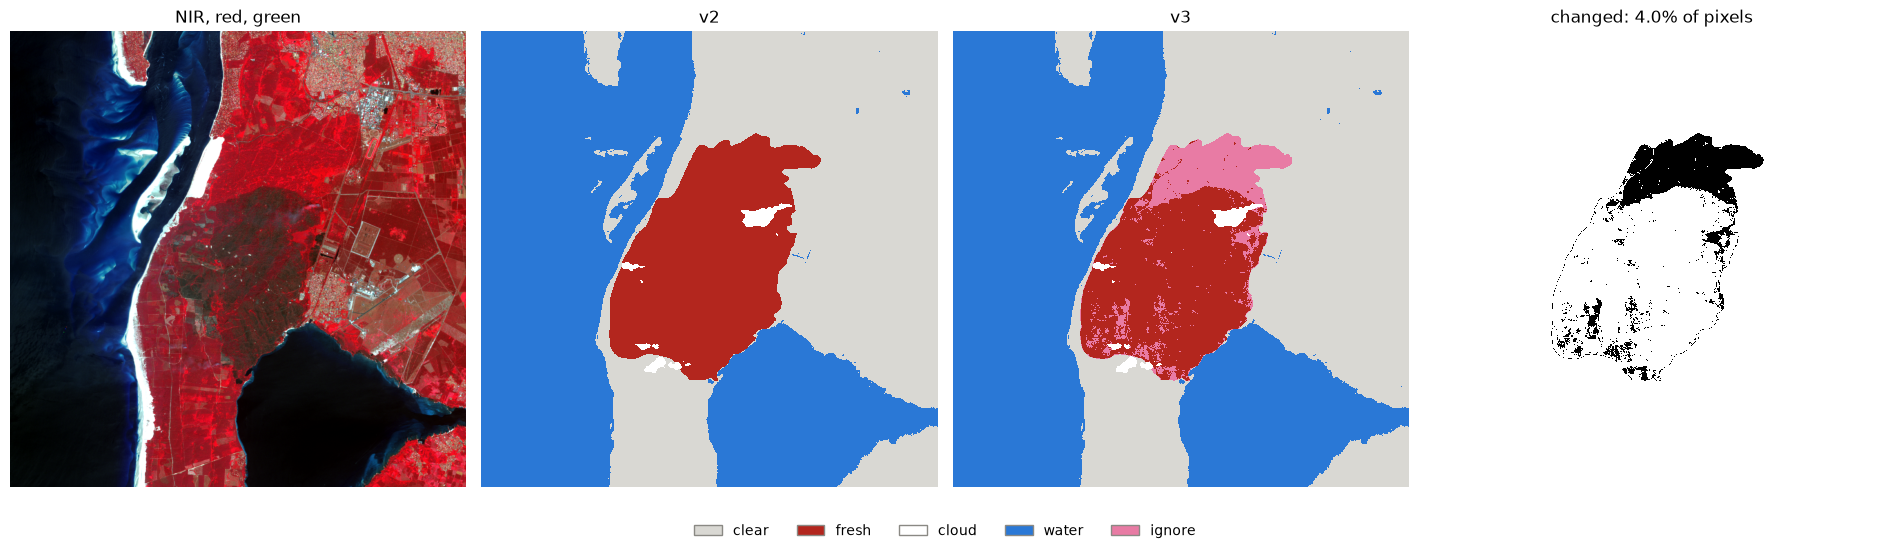

In [11]:
# [6] false colour | v2 | v3 | pixels that changed
def false_colour(img_path, decim):
    with rasterio.open(img_path) as s:
        g, nir = L.green_nir_band_indexes(s)
        h, w = s.height // decim, s.width // decim
        a = s.read([nir, g + 1, g], out_shape=(3, h, w), resampling=Resampling.nearest).astype(np.float32)
    valid = (a > 0).all(0)
    out = np.ones((h, w, 3), np.float32)
    for i in range(3):
        lo, hi = np.percentile(a[i][valid], (2, 98)) if valid.any() else (0, 1)
        out[..., i] = np.clip((a[i] - lo) / max(hi - lo, 1e-6), 0, 1)
    out[~valid] = 1
    return out

def show_v2_v3(res, img_path, decim=4):
    m2, m3 = res["m2"][::decim, ::decim], res["m3"][::decim, ::decim]
    fig, ax = plt.subplots(1, 4, figsize=(19, 5.4))
    ax[0].imshow(false_colour(img_path, decim)); ax[0].set_title("NIR, red, green")
    ax[1].imshow(m2, cmap=CMAP, norm=NORM, interpolation="nearest"); ax[1].set_title("v2")
    ax[2].imshow(m3, cmap=CMAP, norm=NORM, interpolation="nearest"); ax[2].set_title("v3")
    ax[3].imshow(m2 != m3, cmap="Greys", interpolation="nearest")
    ax[3].set_title(f"changed: {(res['m2'] != res['m3']).mean() * 100:.1f}% of pixels")
    for a in ax:
        a.axis("off")
    present = sorted(set(np.unique(res["m2"]).tolist()) | set(np.unique(res["m3"]).tolist()))
    fig.legend(handles=[Patch(facecolor=L.V3_COLORS[v], edgecolor="#8a8984", label=L.V3_NAMES[v]) for v in present],
               loc="lower center", ncol=len(present))
    plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

show_v2_v3(res, L.find_image_for_mask(mask_path), decim=1 if L.source_of(mask_path) == "s2_test" else 4)

## 5 · Dry run on every scene

Writes nothing, takes a few minutes. If the machine runs short of memory, lower `WORKERS` in [1].

In [7]:
# [7] dry run
df = L.run_all(MASKS, fires, cfg, out_path_fn=None, workers=WORKERS)
print(df.status.value_counts().to_string())
if (df.status != "ok").any():
    display(df[df.status != "ok"][["scene", "status"]])
if "warn" in df:
    display(df[df.warn.notna()][["scene", "warn"]])
summ = L.summary_table(df)
summ.pivot(index="cls", columns="source", values=["v2_pct", "v3_pct", "v2_scenes", "v3_scenes"]).round(3)

  25/411 scenes (19s)
  50/411 scenes (30s)
  75/411 scenes (40s)
  100/411 scenes (50s)
  125/411 scenes (60s)
  150/411 scenes (70s)
  175/411 scenes (80s)
  200/411 scenes (90s)
  225/411 scenes (101s)
  250/411 scenes (110s)
  275/411 scenes (120s)
  300/411 scenes (131s)
  325/411 scenes (142s)
  350/411 scenes (151s)
  375/411 scenes (162s)
  400/411 scenes (173s)
  411/411 scenes (179s)
status
ok    411


v2_pct                      v3_pct                     v2_scenes                     v3_scenes                    
source     heo phisat2_sim s2_test     heo phisat2_sim s2_test       heo phisat2_sim s2_test       heo phisat2_sim s2_test
cls                                                                                                                       
clear   42.739      72.387  50.273  44.184      75.619  48.538      25.0       382.0     3.0      25.0       382.0     3.0
cloud   22.194       0.257  26.914  22.194       0.257  26.914      21.0        91.0     2.0      21.0        91.0     2.0
fresh    0.275      10.201   5.263   0.269      10.105   4.905       4.0       372.0     1.0       4.0       373.0     1.0
ignore   0.000       0.000   0.000   0.117       0.717   3.285       0.0         0.0     0.0      13.0       375.0     2.0
nodata  30.680       5.473   0.000  30.680       5.473   0.000      20.0        39.0     0.0      20.0        39.0     0.0
old      1.843       4.333   6.663   0.286       0.473   5.471      16.0       315.0     2.0      10.0       218.0     2.0
shadow   1.896       0.084   5.828   1.896       0.084   5.828      19.0        53.0     1.0      19.0        53.0     1.0
water    0.375       7.265   5.059   0.375       7.272   5.059      22.0       377.0     1.0      22.0       377.0     1.0

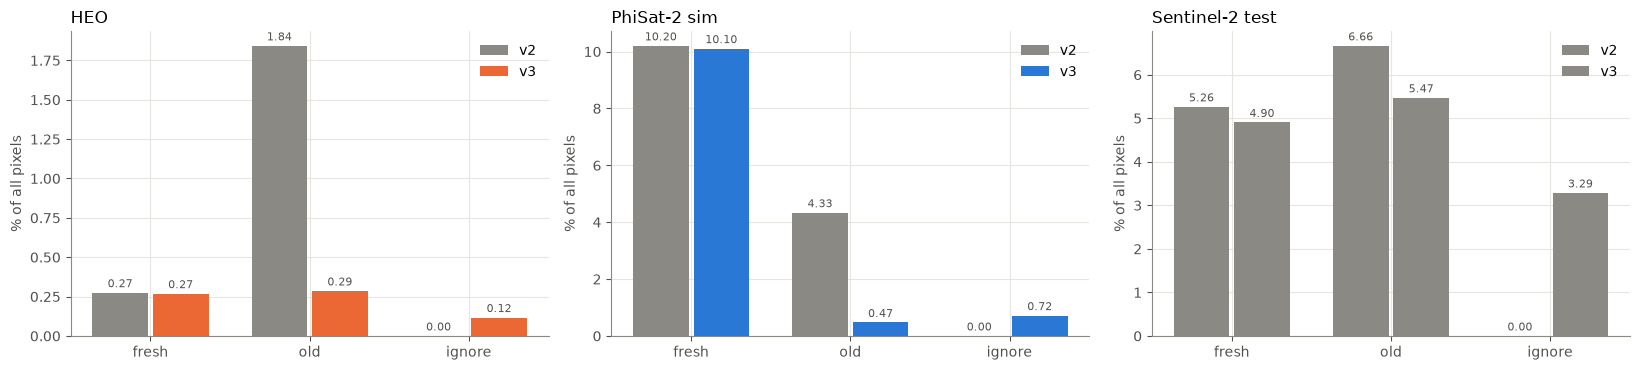

In [8]:
# [8] burn classes and ignore, v2 against v3 (% of all pixels)
burn = summ[summ.cls.isin(["fresh", "old", "ignore"]) & ((summ.v2_pct > 0) | (summ.v3_pct > 0))]
srcs = list(burn.source.unique())
fig, axes = plt.subplots(1, len(srcs), figsize=(5.5 * len(srcs), 3.8), squeeze=False)
for ax, src in zip(axes[0], srcs):
    g = burn[burn.source == src]
    x, w = np.arange(len(g)), 0.38
    b2 = ax.bar(x - w / 2, g.v2_pct, w * 0.92, color=C_GREY, label="v2")
    b3 = ax.bar(x + w / 2, g.v3_pct, w * 0.92, color=SRC_COLOR[src], label="v3")
    ax.bar_label(b2, fmt="%.2f", fontsize=8, color=INK2, padding=2)
    ax.bar_label(b3, fmt="%.2f", fontsize=8, color=INK2, padding=2)
    ax.set_xticks(x); ax.set_xticklabels(g.cls)
    ax.set_title(SRC_NAME.get(src, src), loc="left")
    ax.set_ylabel("% of all pixels")
    ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

In [9]:
# [9] the scenes that changed most, and those where fresh burn changed most (look at them with SAMPLE in [5])
df["d_fresh"] = df.v3_fresh - df.v2_fresh
cols = ["scene", "source", "n_fires_fresh", "n_fires_old", "n_fires_older",
        "v2_fresh", "v3_fresh", "v2_old", "v3_old", "v3_ignore", "changed_px"]
print("most changed:")
display(df.sort_values("changed_px", ascending=False)[cols].head(10))
print("largest change in fresh burn:")
display(df.reindex(df.d_fresh.abs().sort_values(ascending=False).index)[cols + ["d_fresh"]].head(5))

most changed:


,scene,source,n_fires_fresh,n_fires_old,n_fires_older,v2_fresh,v3_fresh,v2_old,v3_old,v3_ignore,changed_px
192,effis_275382_2025-08-21T09-50-25,phisat2_sim,14,15,200,197149,301458,7395028,82736,79539,7388690
205,effis_277936_2025-10-10T11-29-51,phisat2_sim,2,0,5,2836288,2771303,5588897,0,110063,5684751
21,IMH09_1CST__OPT8_20260722T124551_20260722T1245...,heo,8,5,55,900433,828535,5447987,44783,124339,5507146
373,effis_561729_2026-08-04T10-00-23,phisat2_sim,20,27,200,864841,1000960,6328025,1191975,232281,5278575
391,effis_562380_2026-08-04T10-00-09,phisat2_sim,22,12,122,769675,892035,4961622,48051,88050,5045451
161,effis_234943_2024-08-09T10-00-24,phisat2_sim,24,34,144,676674,853161,4772335,363040,140036,4542795
162,effis_235619_2024-08-09T10-00-24,phisat2_sim,22,39,107,553851,726115,5189262,964821,172689,4384019
241,effis_281555_2025-06-27T10-00-39,phisat2_sim,9,32,154,839640,832003,5199929,945465,182543,4334438
196,effis_275731_2025-09-16T10-10-18,phisat2_sim,31,1,122,632286,700694,4189290,735,69594,4298797
237,effis_281259_2025-09-15T10-00-37,phisat2_sim,33,11,178,2002856,2181135,4889723,907301,321916,4226423


largest change in fresh burn:


,scene,source,n_fires_fresh,n_fires_old,n_fires_older,v2_fresh,v3_fresh,v2_old,v3_old,v3_ignore,changed_px,d_fresh
343,effis_52448_2021-10-13T11-19-54,phisat2_sim,1,0,0,8328894,7614592,0,0,740348,740348,-714302
43,effis_205433_2022-07-17T11-08-52,phisat2_sim,1,0,0,2508473,1855811,0,0,665833,665833,-652662
88,effis_214617_2023-04-19T11-29-12,phisat2_sim,7,0,14,4464010,3864218,292263,0,704069,1020040,-599792
219,effis_278475_2025-10-10T11-29-41,phisat2_sim,2,0,14,13237968,12679309,558120,0,612056,1157599,-558659
53,effis_206702_2022-08-12T11-29-31,phisat2_sim,5,2,5,6170220,5685526,347678,174245,625943,754295,-484694


## 6 · Write masks_v3

Set `WRITE = True` once step 5 looks right. It writes the v3 masks next to the v2 ones and overwrites earlier v3 masks of the same scenes (never the v2 masks).

In [12]:
# [10] write
WRITE = True
INDEX = "data/tables/labels_v3_from_v2.csv"

if WRITE:
    dfw = L.run_all(MASKS, fires, cfg, out_path_fn=L.sibling_out_path, workers=WORKERS)
    if (dfw.status != "ok").any():
        display(dfw[dfw.status != "ok"][["scene", "status"]])
    os.makedirs("data/tables", exist_ok=True)
    dfw.to_csv(INDEX, index=False)
    with open(INDEX.replace(".csv", "_config.json"), "w") as f:
        json.dump({**asdict(cfg), "effis": L.EFFIS_FILES, "n_masks": len(MASKS),
                   "created": pd.Timestamp.now().isoformat(),
                   "legend": {str(k): v for k, v in L.V3_NAMES.items()}}, f, indent=2)
    print(dfw.mask_v3.dropna().map(os.path.dirname).value_counts().to_string())
else:
    print("nothing written, set WRITE = True")

  25/411 scenes (17s)
  50/411 scenes (39s)
  75/411 scenes (61s)
  100/411 scenes (72s)
  125/411 scenes (83s)
  150/411 scenes (94s)
  175/411 scenes (106s)
  200/411 scenes (117s)
  225/411 scenes (129s)
  250/411 scenes (140s)
  275/411 scenes (151s)
  300/411 scenes (163s)
  325/411 scenes (174s)
  350/411 scenes (184s)
  375/411 scenes (196s)
  400/411 scenes (208s)
  411/411 scenes (215s)
mask_v3
data/phisat2_sim/masks_v3    383
data/heo/masks_v3             25
data/s2_test/masks_v3          3


## 7 · What was written

In [13]:
# [11] open one written mask and check its values and tags
written = sorted(glob.glob("data/*/masks_v3/*_mask.tif"))
print(len(written), "v3 masks on disk:", pd.Series([L.source_of(w) for w in written]).value_counts().to_dict())
if written:
    with rasterio.open(written[0]) as s:
        print(written[0]); print(s.tags())
        v, c = np.unique(s.read(1), return_counts=True)
        print({L.V3_NAMES.get(int(k), int(k)): int(n) for k, n in zip(v, c)})

411 v3 masks on disk: {'phisat2_sim': 383, 'heo': 25, 's2_test': 3}
data/heo/masks_v3/IMH01_1CST__OPT8_20250709T100945_20250709T100947_20260330T172935_02623______O_A02_mask.tif
{'BRIGHT_MAX': '0.3', 'EDGE_M': '10.0', 'FRESH_MAX_D': '90.0', 'IGNORE_MAX_D': '365.0', 'LABEL_VERSION': 'v3', 'LEGEND': '{"0": "clear", "2": "fresh", "3": "old", "4": "cloud", "5": "shadow", "6": "water", "254": "ignore", "255": "nodata"}', 'NDVI_MAX': '0.5', 'OLD_MAX_D': '365.0', 'AREA_OR_POINT': 'Area'}
{'clear': 12280700, 'fresh': 48492, 'old': 196636, 'cloud': 4421074, 'shadow': 2390582, 'water': 2005902, 'ignore': 100824, 'nodata': 8921380}


pixels                         km²                     % of data                    
              heo phisat2_sim s2_test     heo phisat2_sim s2_test       heo phisat2_sim s2_test
clear   343004134  4859023760   95430  2143.8    109631.7     9.5    63.739      79.997  48.538
fresh     2086081   649298762    9643    13.0     14649.8     1.0     0.388      10.690   4.905
old       2220251    30378700   10756    13.9       685.4     1.1     0.413       0.500   5.471
cloud   172290994    16491107   52915  1076.8       372.1     5.3    32.016       0.272  26.914
shadow   14715741     5416126   11459    92.0       122.2     1.1     2.735       0.089   5.828
water     2910365   467303211    9946    18.2     10543.5     1.0     0.541       7.694   5.059
ignore     909120    46074195    6459     5.7      1039.5     0.6     0.169       0.759   3.285
nodata  238170019   351687867       0  1488.6      7935.0     0.0       NaN         NaN     NaN

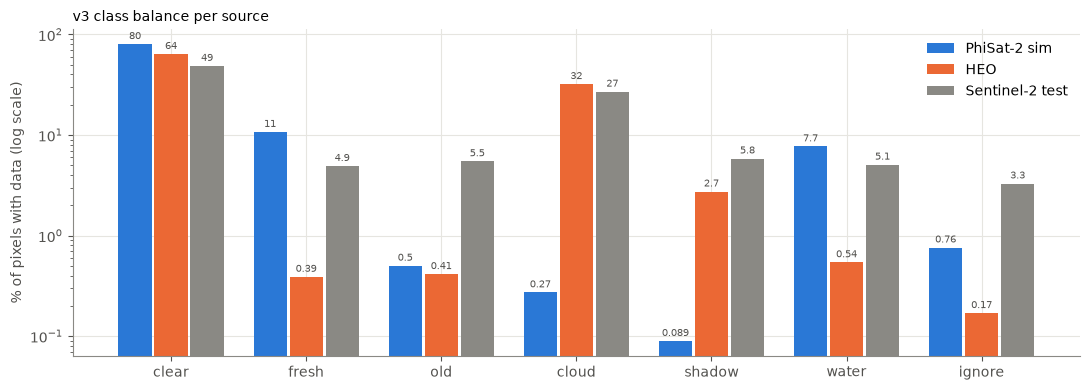

In [14]:
# [12] class balance of the written masks: pixels, km² and % of the pixels that have data
idx = pd.read_csv(INDEX)
names = list(L.V3_NAMES.values())
px = pd.DataFrame({s: {n: int(g[f"v3_{n}"].sum()) for n in names} for s, g in idx.groupby("source")})
km2 = pd.DataFrame({s: {n: (g[f"v3_{n}"] * g.px_m ** 2).sum() / 1e6 for n in names} for s, g in idx.groupby("source")})
pct = 100 * px.drop("nodata") / px.drop("nodata").sum()
display(pd.concat({"pixels": px, "km²": km2.round(1), "% of data": pct.round(3)}, axis=1))

cls = [n for n in names if n != "nodata"]
srcs = [s for s in ["phisat2_sim", "heo", "s2_test"] if s in pct.columns]
fig, ax = plt.subplots(figsize=(11, 4))
w = 0.8 / len(srcs)
for i, src in enumerate(srcs):
    bars = ax.bar(np.arange(len(cls)) + (i - (len(srcs) - 1) / 2) * w, pct.loc[cls, src].clip(lower=1e-4), w * 0.92,
                  color=SRC_COLOR[src], label=SRC_NAME[src])
    ax.bar_label(bars, labels=[f"{v:.2g}" for v in pct.loc[cls, src]], fontsize=7, color=INK2, padding=2)
ax.set_yscale("log"); ax.set_xticks(np.arange(len(cls))); ax.set_xticklabels(cls)
ax.set_ylabel("% of pixels with data (log scale)")
ax.set_title("v3 class balance per source", loc="left", fontsize=10)
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()